In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.preprocessing import scale

#data from here: https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering
#original data source here: https://archive.ics.uci.edu/ml/datasets/wine

#import data
wine = pd.read_csv("wine_clustering.csv")#again, you should put the path on your machine here
wine.head()



,Label,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [2]:
#grab "ground truth" labels
labels = wine["Label"]

#remove labels from data set to use for clustering
dataForClustering = pd.DataFrame(scale(wine.loc[:, wine.columns != "Label"]))
dataForClustering.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [3]:
km_clust = KMeans(3) #declare model
km_clust.fit(dataForClustering) #fit model to data

#look at labels
km_clust.labels_

C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 2, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2], dtype=int32)

In [4]:
#if you have known labels, the "rand score" is similar to the accuracy score
# we calculated when doing supervised learning (its in fact the same if there
#are only two classes). If labels are not known, rand score can tell you the
#similarity between two different clustering methods
metrics.rand_score(labels, km_clust.labels_)

0.9310607503332698

In [5]:
# if you do not have ground truth labels, you can evaluate clusters by 
# looking at how separated they are in n-dimensional space
#lower values are better - only useful if you want to compare to other clustering metrics
metrics.davies_bouldin_score(dataForClustering, km_clust.labels_)

1.393136248943783

# How to visualize clusters?
N-dimensional data exists n-dimensional space (for example, the iris data has 4 columns and would then be plotted in 4-dimensional space). To visualize these clusters, we would like to compress the data into 2 dimensions. This process is called **dimensionality reduction**. Principal components analysis is the most common way to do this (but there are many others as well). 

In [6]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2) #determine how many dimensions you want output
components = pca.fit_transform(dataForClustering)
# for a data set with n rows, will return an nx2 numpy array
print(type(components))
print(components)

<class 'numpy.ndarray'>
[[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]
 [ 3.75706561  2.75637191]
 [ 1.00890849  0.86983082]
 [ 3.05025392  2.12240111]
 [ 2.44908967  1.17485013]
 [ 2.05943687  1.60896307]
 [ 2.5108743   0.91807096]
 [ 2.75362819  0.78943767]
 [ 3.47973668  1.30233324]
 [ 1.7547529   0.61197723]
 [ 2.11346234  0.67570634]
 [ 3.45815682  1.13062988]
 [ 4.31278391  2.09597558]
 [ 2.3051882   1.66255173]
 [ 2.17195527  2.32730534]
 [ 1.89897118  1.63136888]
 [ 3.54198508  2.51834367]
 [ 2.0845222   1.06113799]
 [ 3.12440254  0.78689711]
 [ 1.08657007  0.24174355]
 [ 2.53522408 -0.09184062]
 [ 1.64498834 -0.51627893]
 [ 1.76157587 -0.31714893]
 [ 0.9900791   0.94066734]
 [ 1.77527763  0.68617513]
 [ 1.23542396 -0.08980704]
 [ 2.18840633  0.68956962]
 [ 2.25610898  0.19146194]
 [ 2.50022003  1.24083383]
 [ 2.67741105  1.47187365]
 [ 1.62857912  0.05270445]
 [ 1.90269086  1.63306043]
 [ 1.41038853  0.69793432]
 [ 1.90382623  0.17671095]
 [ 1

Text(0, 0.5, 'PC 2')

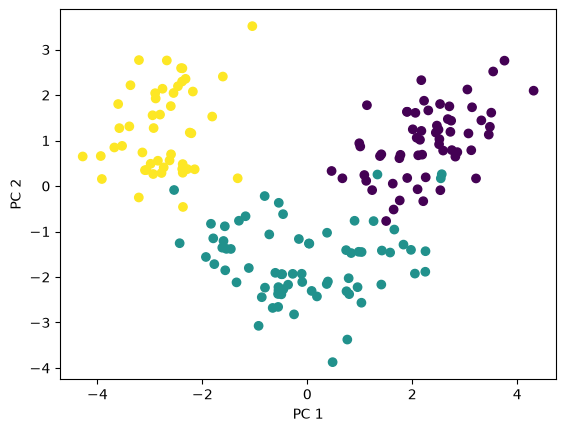

In [7]:
import matplotlib.pyplot as plt

# we can plot these colored by the labels we calculated to see if 
# the clusters seem to fit based on the data
plt.scatter(components[:,0], components[:,1], c = labels)
plt.xlabel("PC 1")
plt.ylabel("PC 2")


In [8]:
# a common way to evaluate pca is "% varience explained"
pca.explained_variance_ratio_

array([0.36198848, 0.1920749 ])

# Hierarchical clustering

In [9]:
from sklearn.cluster import AgglomerativeClustering

#We'll start by letting the clustering algorithm try to deterine
# wine clusters
hier_clust = AgglomerativeClustering()
hier_clust.fit(dataForClustering)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",2
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_sampl

In [10]:
# How many clusters did the algorithm find?
hier_clust.n_clusters

2

Text(0, 0.5, 'PC 2')

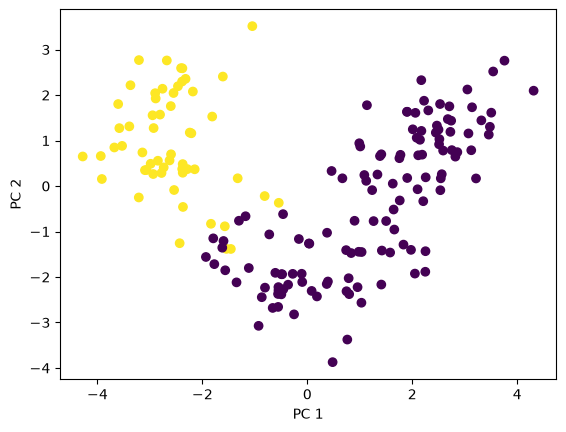

In [11]:
# lets see how it did the clustering
plt.scatter(components[:,0], components[:,1], c = hier_clust.labels_)
plt.xlabel("PC 1")
plt.ylabel("PC 2")



In [12]:
# obviously, because the algorithm made two clusters when we know that there 
# are three different vinyards, this algorithm is not going to have
# a very good Rand index (accuracy)

metrics.rand_score(labels, hier_clust.labels_)

0.7076747286231194

In [13]:
# does the algorithm do better if we force 3 clusters?
hier_clust2 = AgglomerativeClustering(n_clusters = 3)
hier_clust2.fit(dataForClustering)
metrics.rand_score(labels, hier_clust2.labels_)

0.9064940011426394

Text(0, 0.5, 'PC 2')

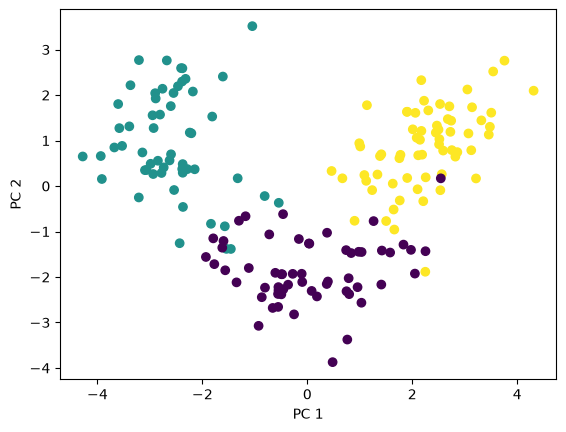

In [14]:
# we got a worse rand score as using k-means clustering
# How similar are the two clustering algorithms?
# lets see how it did the clustering
plt.scatter(components[:,0], components[:,1], c = hier_clust2.labels_)
plt.xlabel("PC 1")
plt.ylabel("PC 2")



In [15]:
# We can verify this using rand index
# to compare the two clustering algorithm's outputs
metrics.rand_score(km_clust.labels_, hier_clust2.labels_)

0.9026852028185107

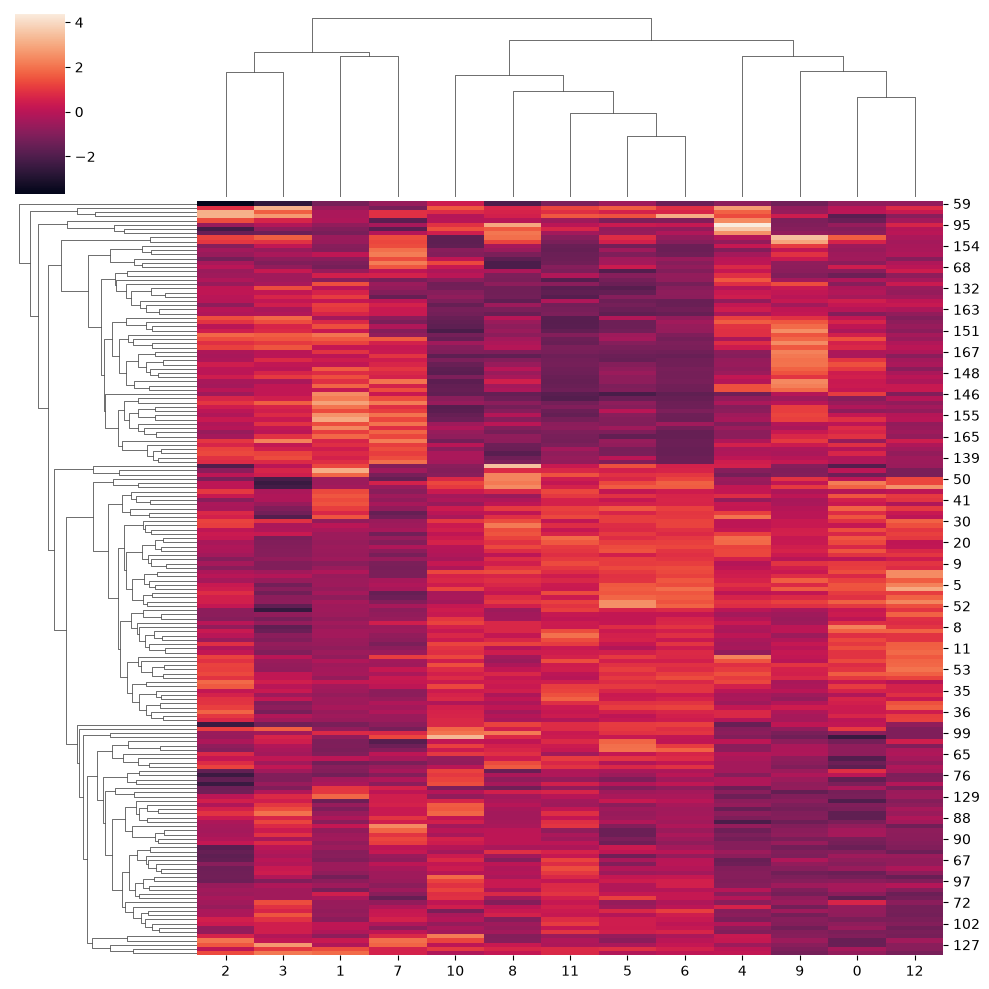

In [16]:
# so what is actually going on with hierarchical clustering? 
# one of the outputs of a hierarchical clustering algorithm is 
# a tree called a dendrogram. Lets look at one:
import seaborn as sns
sns.clustermap(dataForClustering)

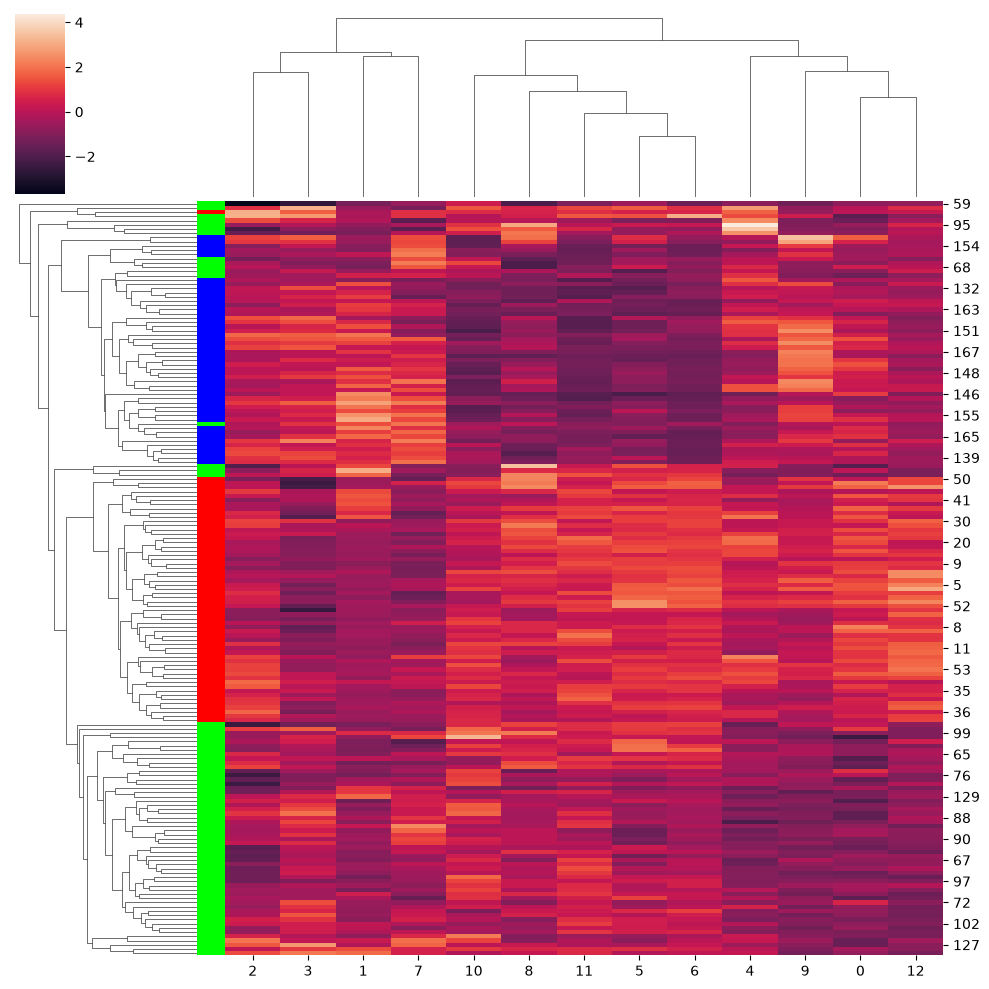

In [17]:
# we can add colors for the labels on the observations to see more clearly 
# what is going on in the data
rgb = []
for i in labels:
    if i == 1:
        rgb.append((1,0,0)) #rgb code for red
    elif i == 2:
        rgb.append((0,1,0)) #rgb code for green
    elif i == 3:
        rgb.append((0,0,1)) #rgb code for blue
        
sns.clustermap(dataForClustering, row_colors = rgb)

# Your turn - determine how many different types of customers you thing a mall should try to target with targeted advertising

Download Mall_Customers.csv from canvas and see what you can find

I would recommend doing the following steps:

1) do pca on the data set and plot it to get a visual of how the data looks (already done for you)

2) use one of the clustering methods varying the number of clusters and determine the davies-bouldin score (because we don't know the labels)

3) judge which number of clusters you think is best

4) Display the graph illustrating how many clusters you think is best (you should have each cluster have a distinct color)

Text(0, 0.5, 'PC 2')

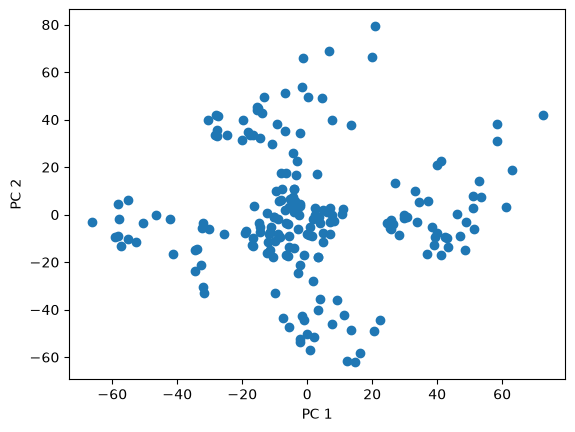

In [18]:
mall = pd.read_csv("Mall_Customers.csv")

# do PCA first
pca = PCA(n_components=2) # say how many dimensions you want
components = pca.fit_transform(mall)

plt.scatter(components[:,0], components[:,1])
plt.xlabel("PC 1")
plt.ylabel("PC 2")

In [19]:
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(mall)
    print(k, metrics.davies_bouldin_score(mall, km.labels_))

C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


2 1.3571023143309133
3 0.8748062648492884
4 0.8914904209843171
5 0.8218781633199779


C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


6 0.7469740072755284
7 0.7947856168898563
8 0.8638554586521907


C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


9 0.8921710214929782
10 0.9574854229479305


C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


C:\Users\huelkes\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


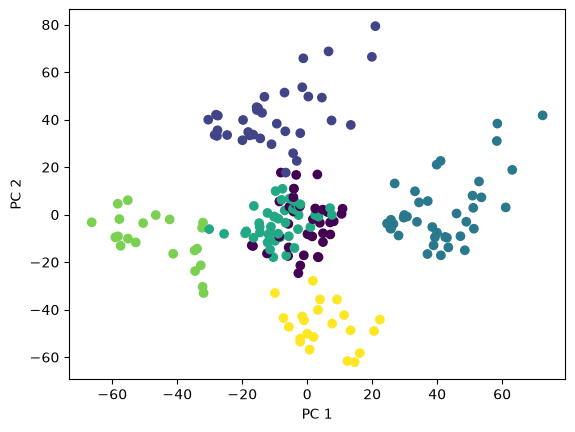

In [20]:
best_k = 6  

km = KMeans(n_clusters=best_k, n_init=10, random_state=0)
km.fit(mall)

plt.scatter(components[:,0], components[:,1], c=km.labels_)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()

In [21]:
mall.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [22]:
#I used k-means with 2–10 clusters and compared Davies-Bouldin scores
# The lowest score was 0.747 at k = 6, so I’d recommend the mall target 6 customer groups. 